In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240612_TS_C10_W20_11mM_run3.DSC", exp_type="francklab_esr/romana") # cooling 2 --initial sample
d2 = find_file("240612_TS_C10_W20_11mM_run4.DSC", exp_type="francklab_esr/romana") # heating 2 subsequently --after cooling and heating

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'cooling 2')

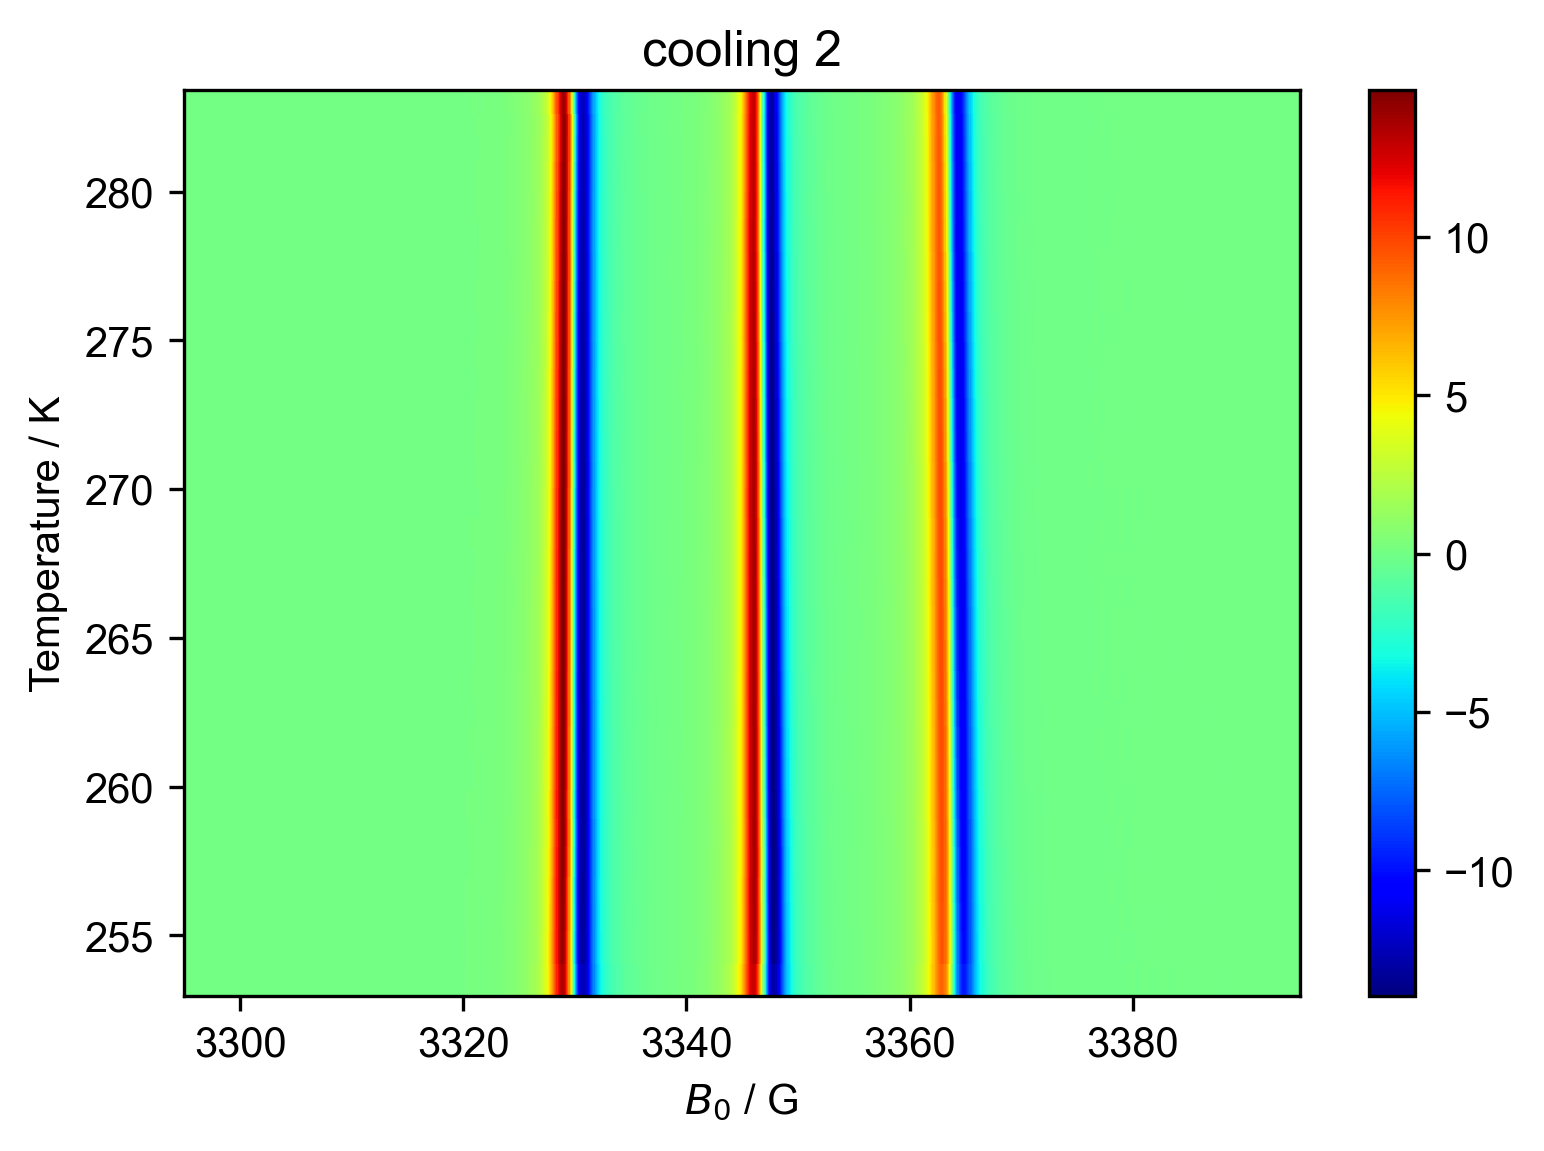

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("cooling 2")

Text(0.5, 1.0, 'heating 2')

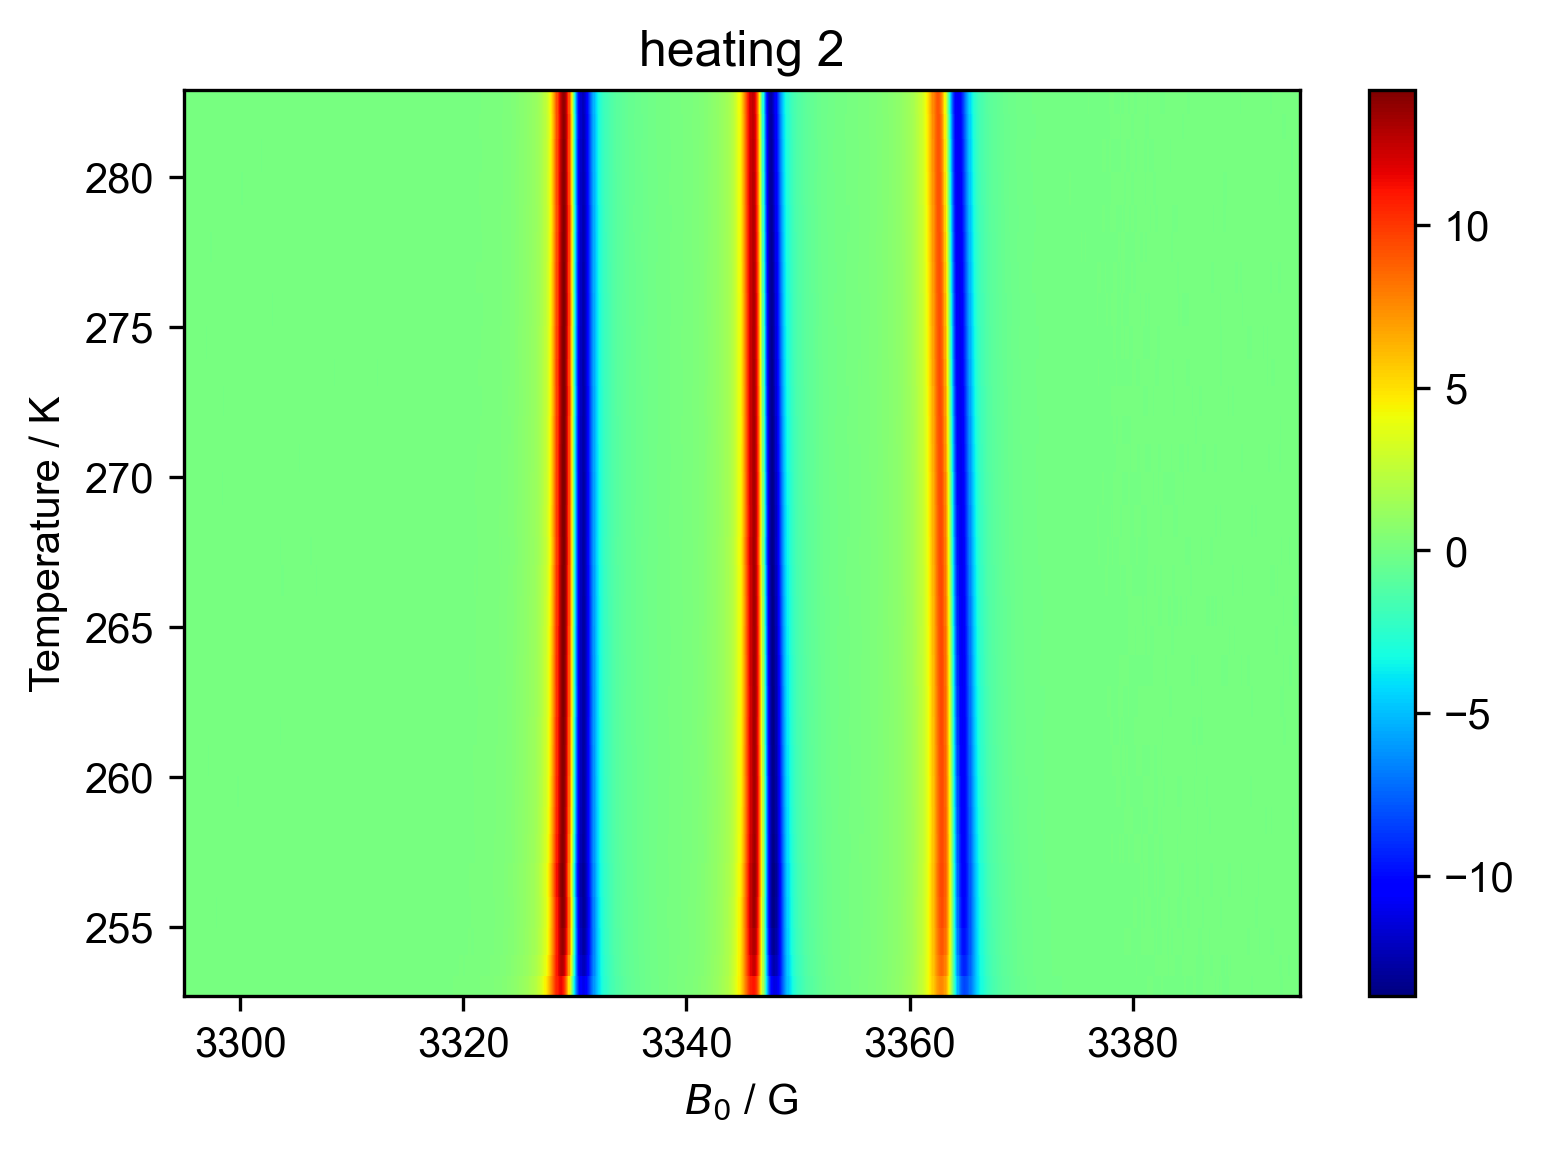

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("heating 2")

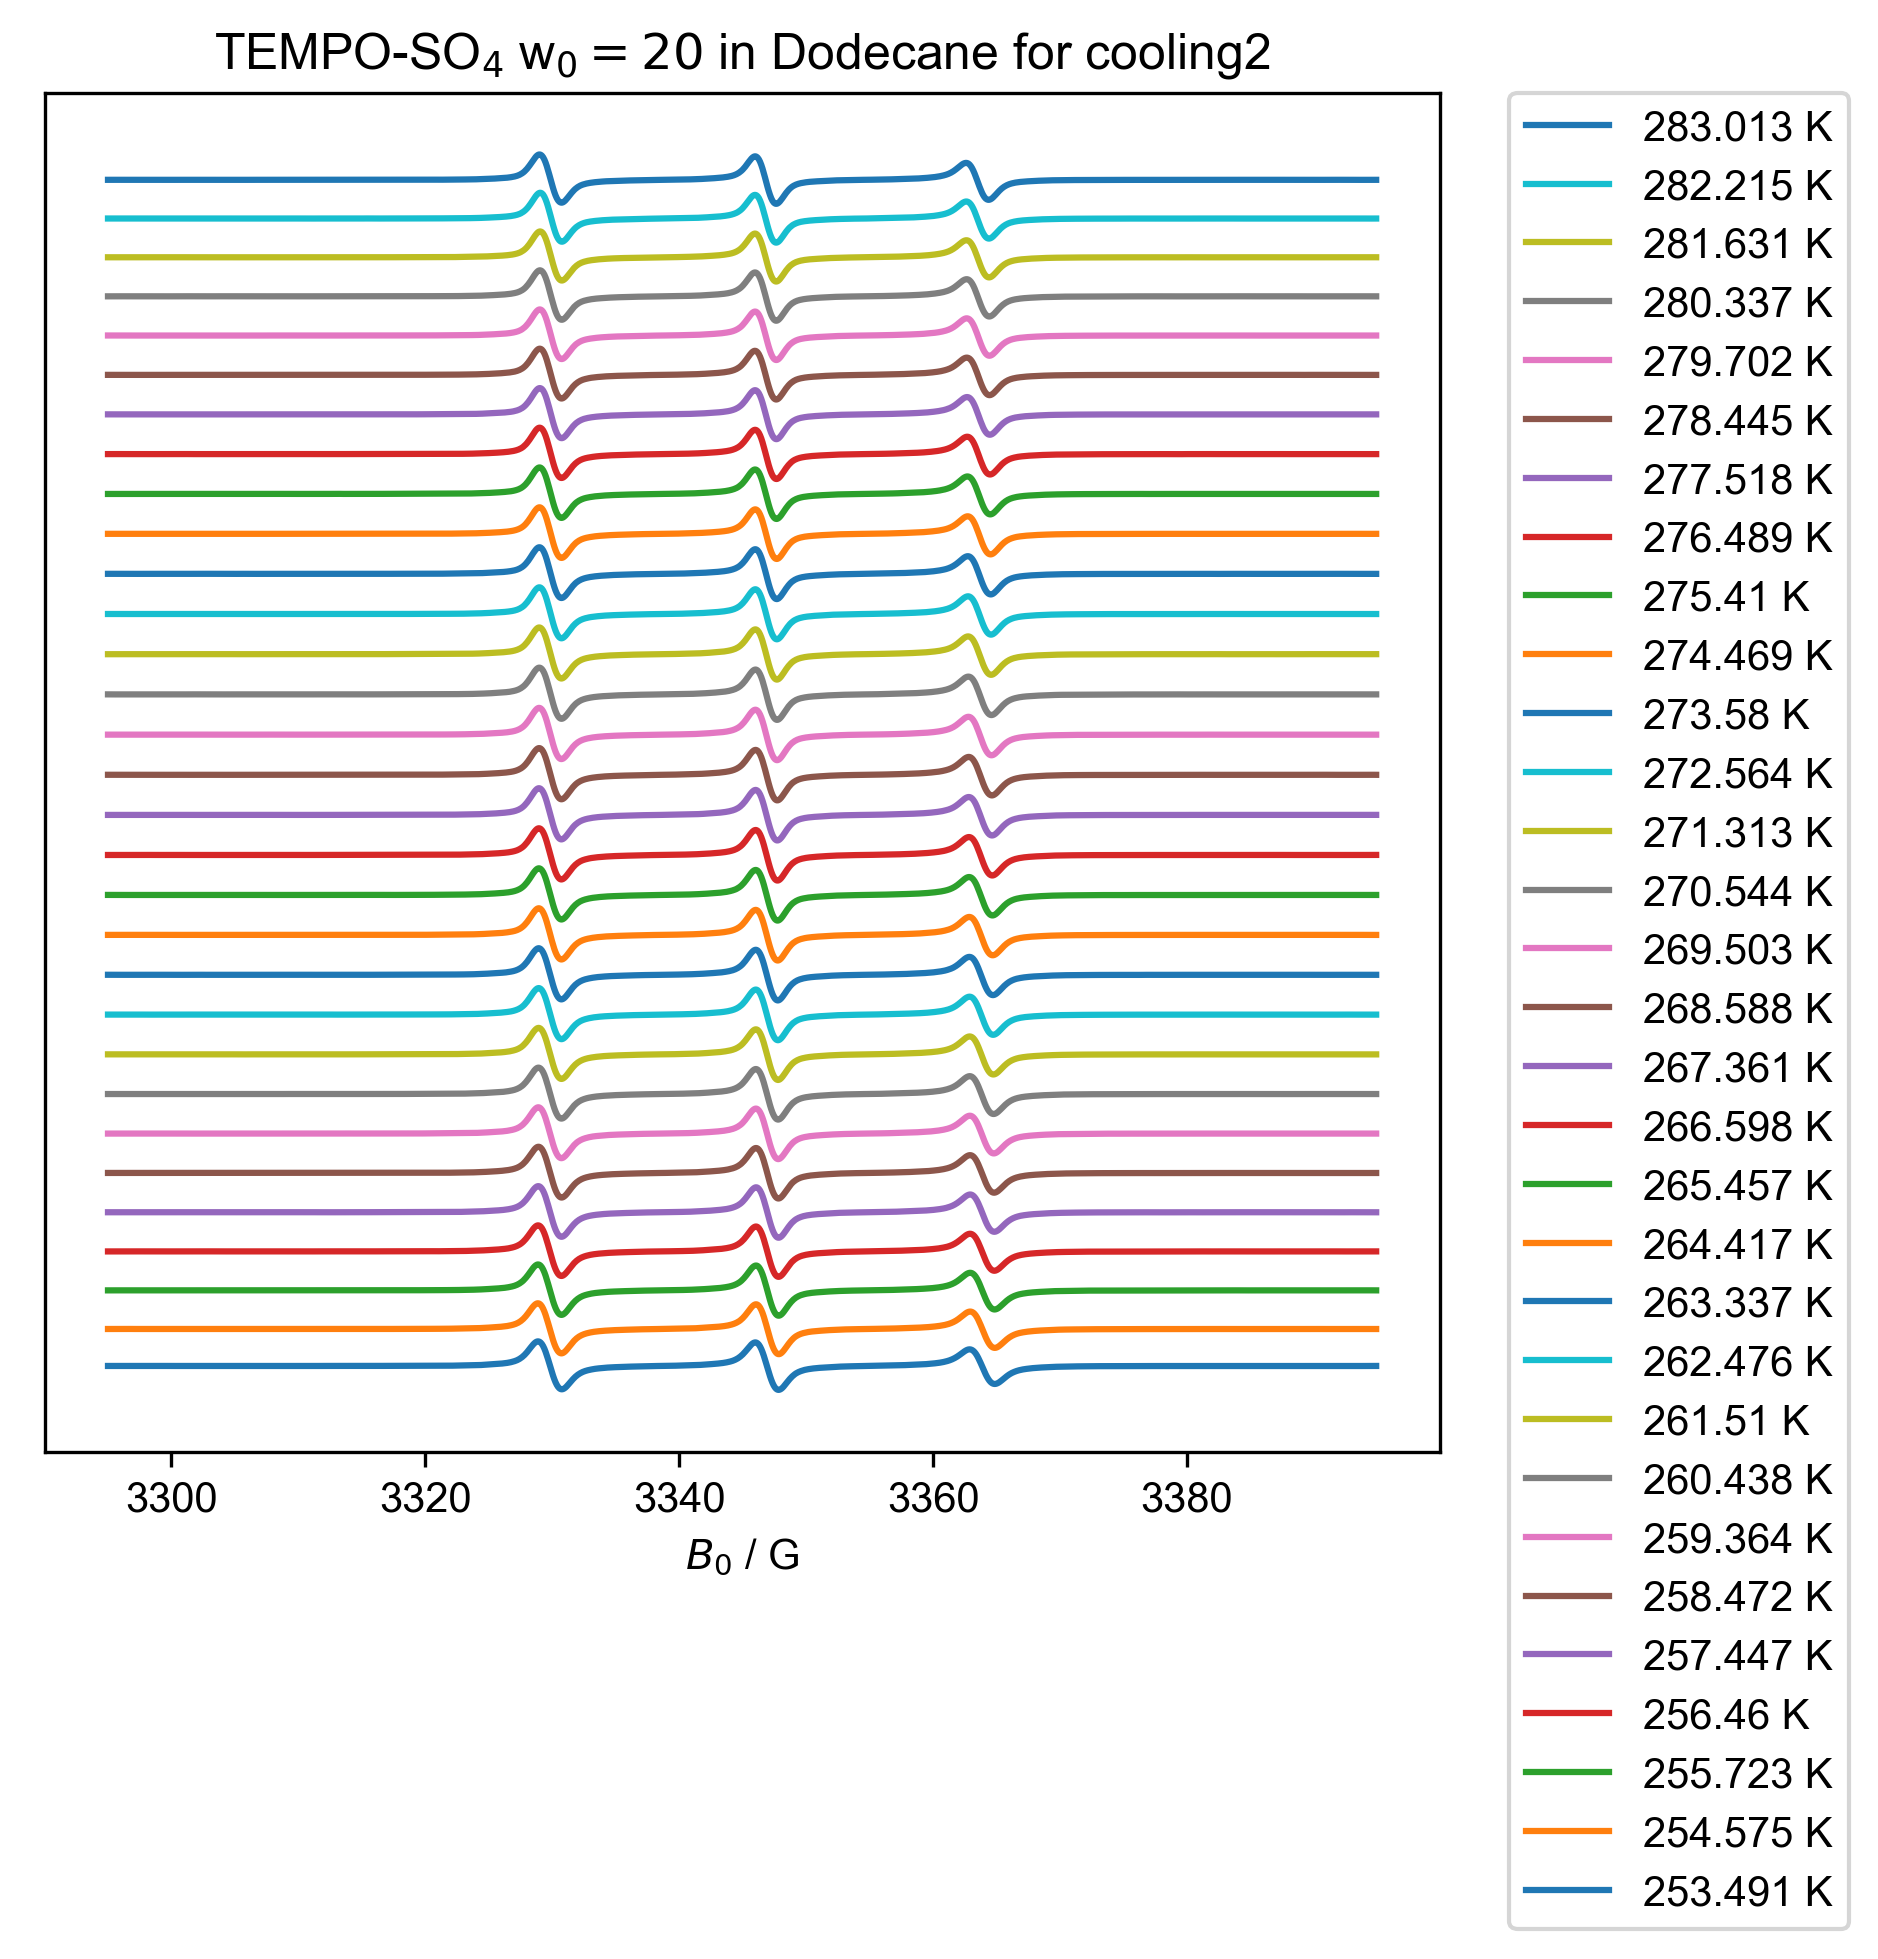

In [9]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling2", (200, 300))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

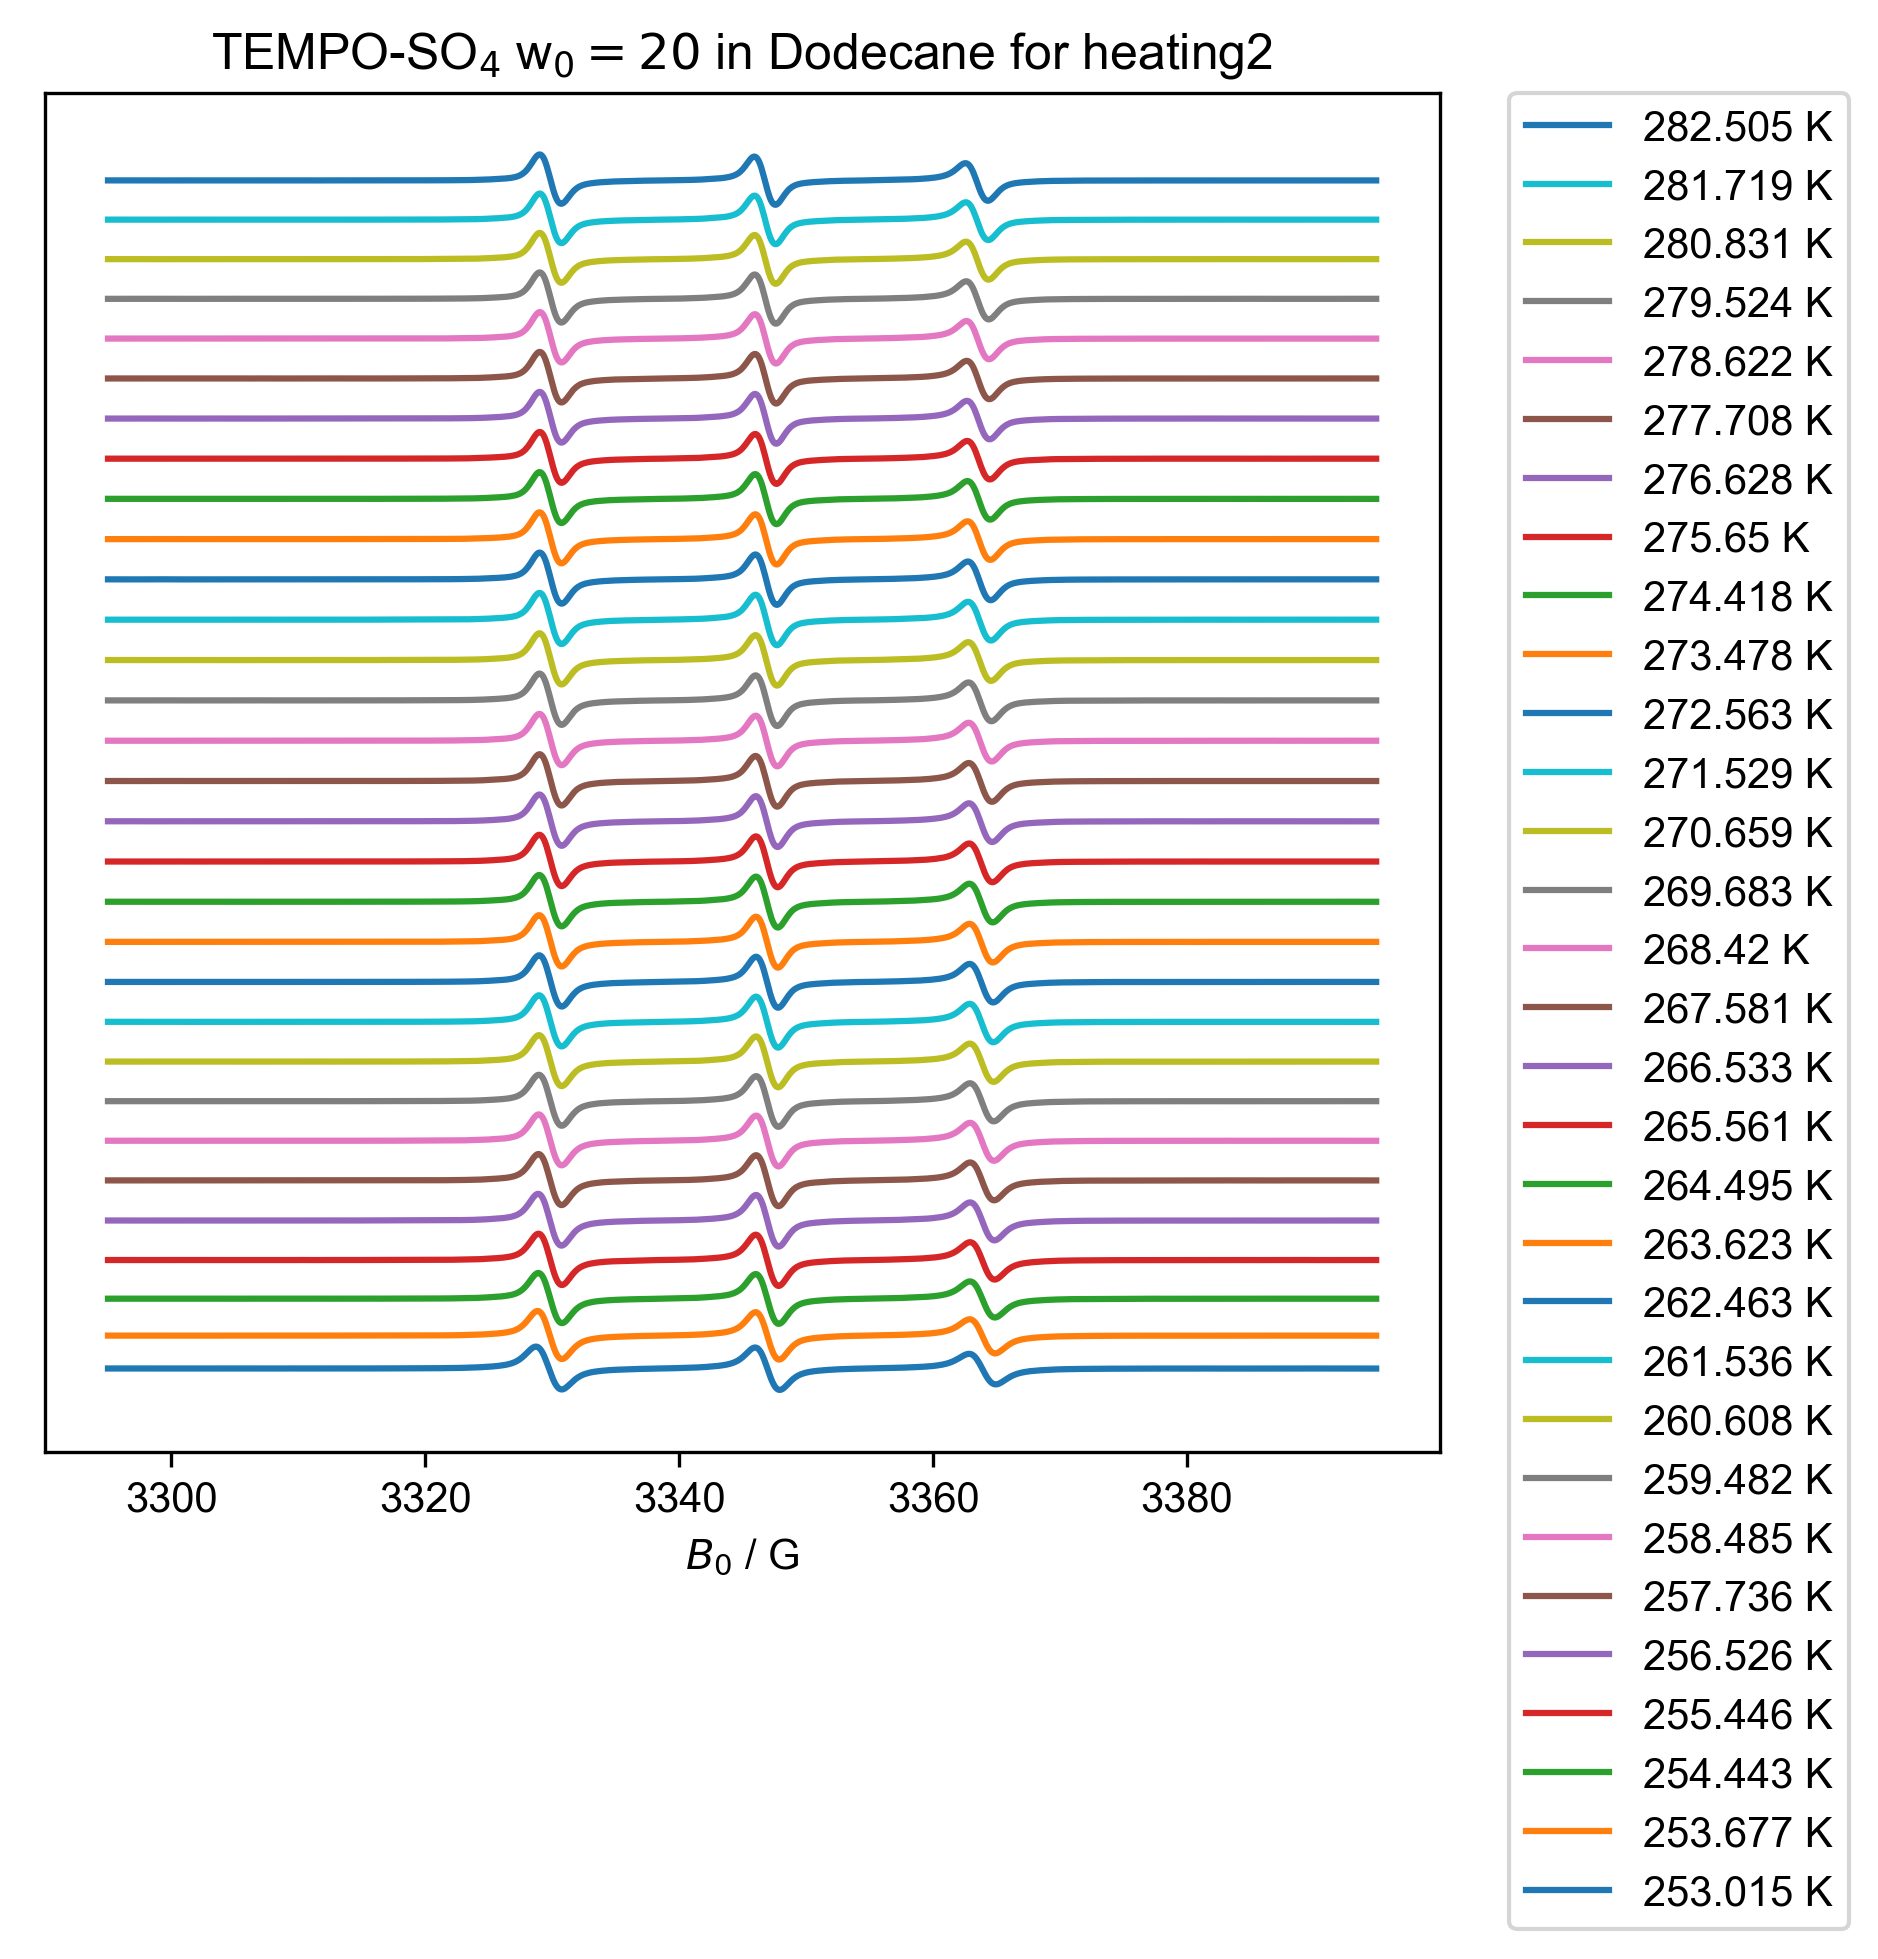

In [10]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0=20$ in Dodecane for heating2", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

[253.491 254.575 255.723 256.46  257.447 258.472 259.364 260.438 261.51
 262.476 263.337 264.417 265.457 266.598 267.361 268.588 269.503 270.544
 271.313 272.564 273.58  274.469 275.41  276.489 277.518 278.445 279.702
 280.337 281.631 282.215 283.013]
[253.015 253.677 254.443 255.446 256.526 257.736 258.485 259.482 260.608
 261.536 262.463 263.623 264.495 265.561 266.533 267.581 268.42  269.683
 270.659 271.529 272.563 273.478 274.418 275.65  276.628 277.708 278.622
 279.524 280.831 281.719 282.505]


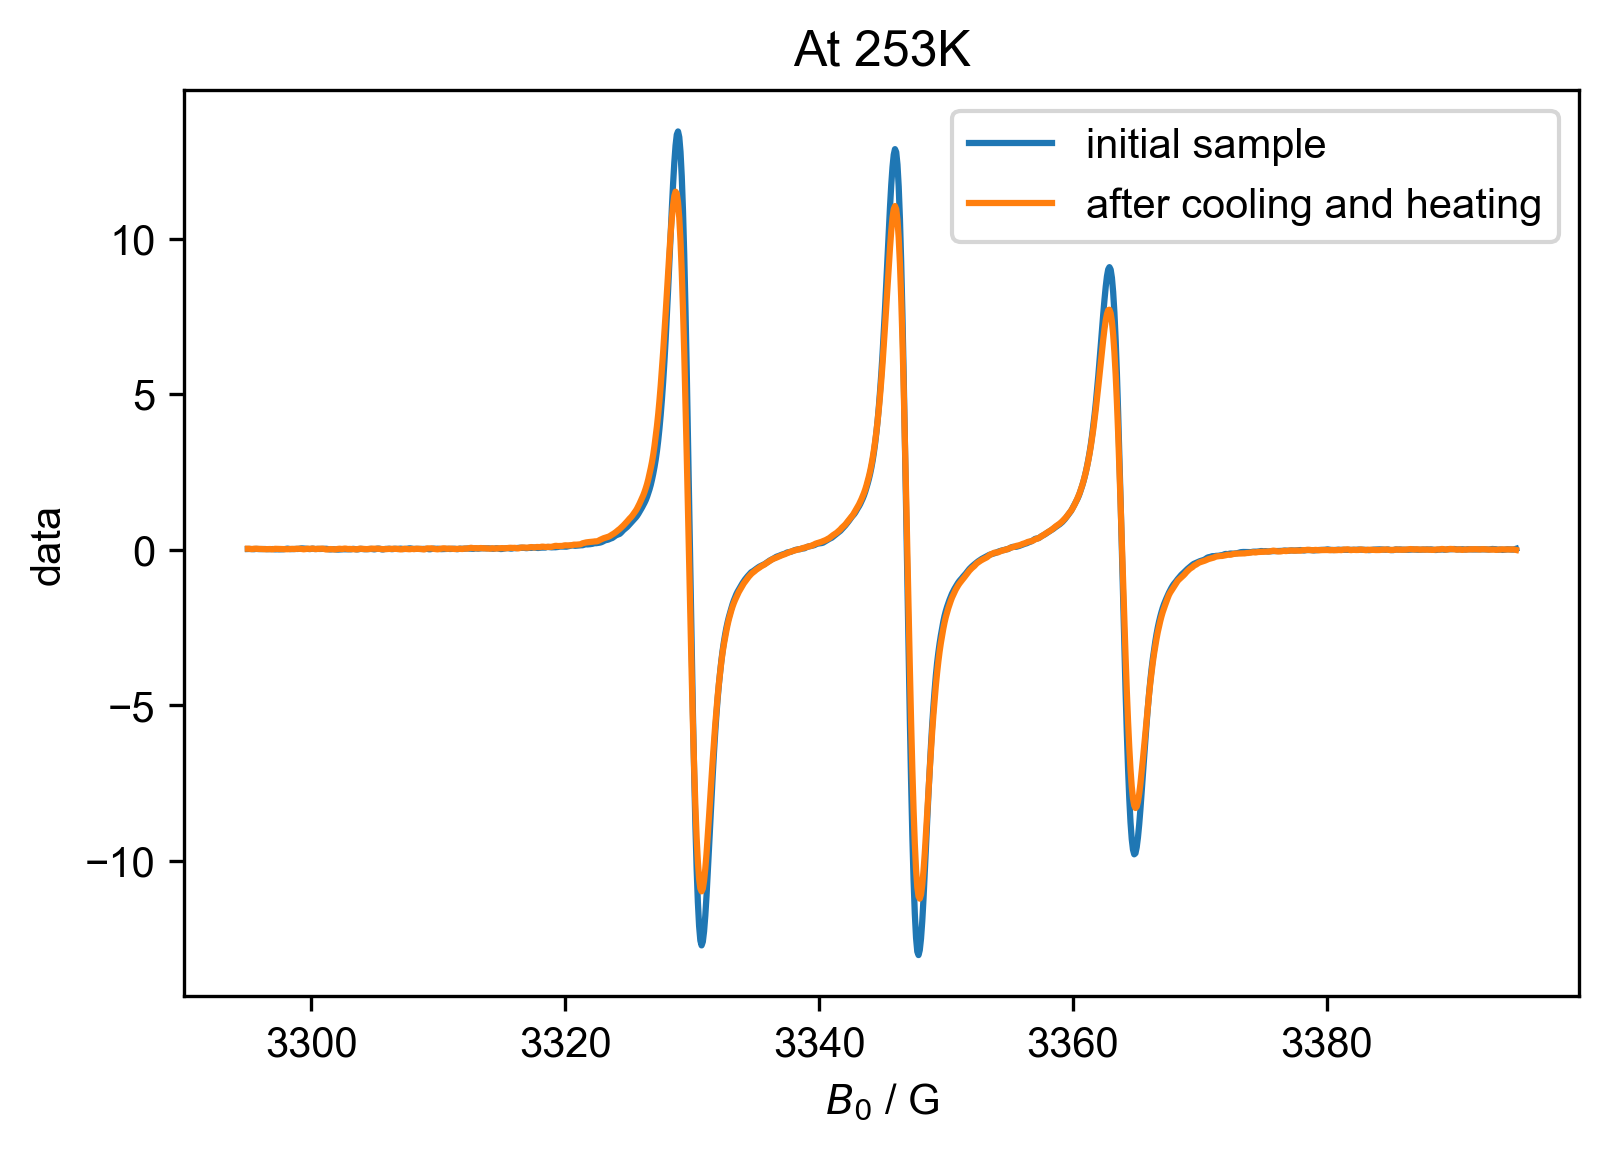

In [11]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="initial sample")
plot(d2["Temperature":253], label="after cooling and heating")
title("At 253K")
legend()

[253.491 254.575 255.723 256.46  257.447 258.472 259.364 260.438 261.51
 262.476 263.337 264.417 265.457 266.598 267.361 268.588 269.503 270.544
 271.313 272.564 273.58  274.469 275.41  276.489 277.518 278.445 279.702
 280.337 281.631 282.215 283.013]
[253.015 253.677 254.443 255.446 256.526 257.736 258.485 259.482 260.608
 261.536 262.463 263.623 264.495 265.561 266.533 267.581 268.42  269.683
 270.659 271.529 272.563 273.478 274.418 275.65  276.628 277.708 278.622
 279.524 280.831 281.719 282.505]


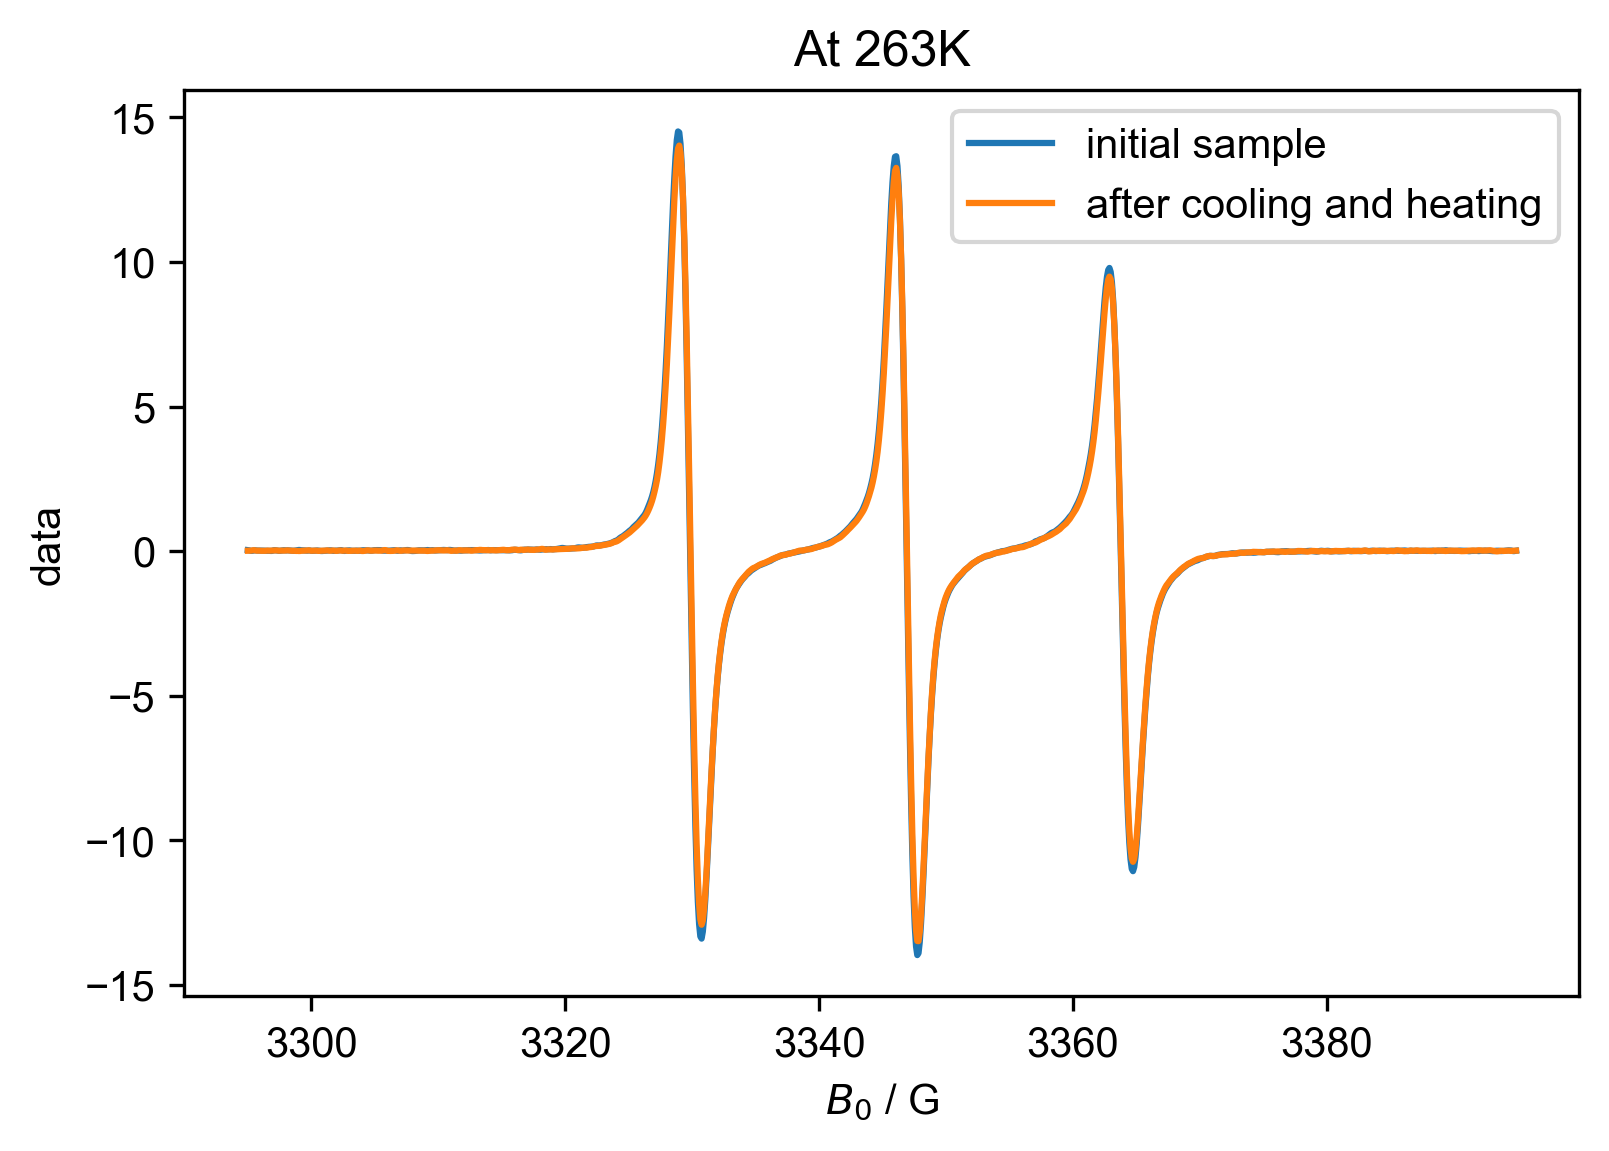

In [12]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="initial sample")
plot(d2["Temperature":263], label="after cooling and heating")
title("At 263K")
legend()

[253.491 254.575 255.723 256.46  257.447 258.472 259.364 260.438 261.51
 262.476 263.337 264.417 265.457 266.598 267.361 268.588 269.503 270.544
 271.313 272.564 273.58  274.469 275.41  276.489 277.518 278.445 279.702
 280.337 281.631 282.215 283.013]
[253.015 253.677 254.443 255.446 256.526 257.736 258.485 259.482 260.608
 261.536 262.463 263.623 264.495 265.561 266.533 267.581 268.42  269.683
 270.659 271.529 272.563 273.478 274.418 275.65  276.628 277.708 278.622
 279.524 280.831 281.719 282.505]


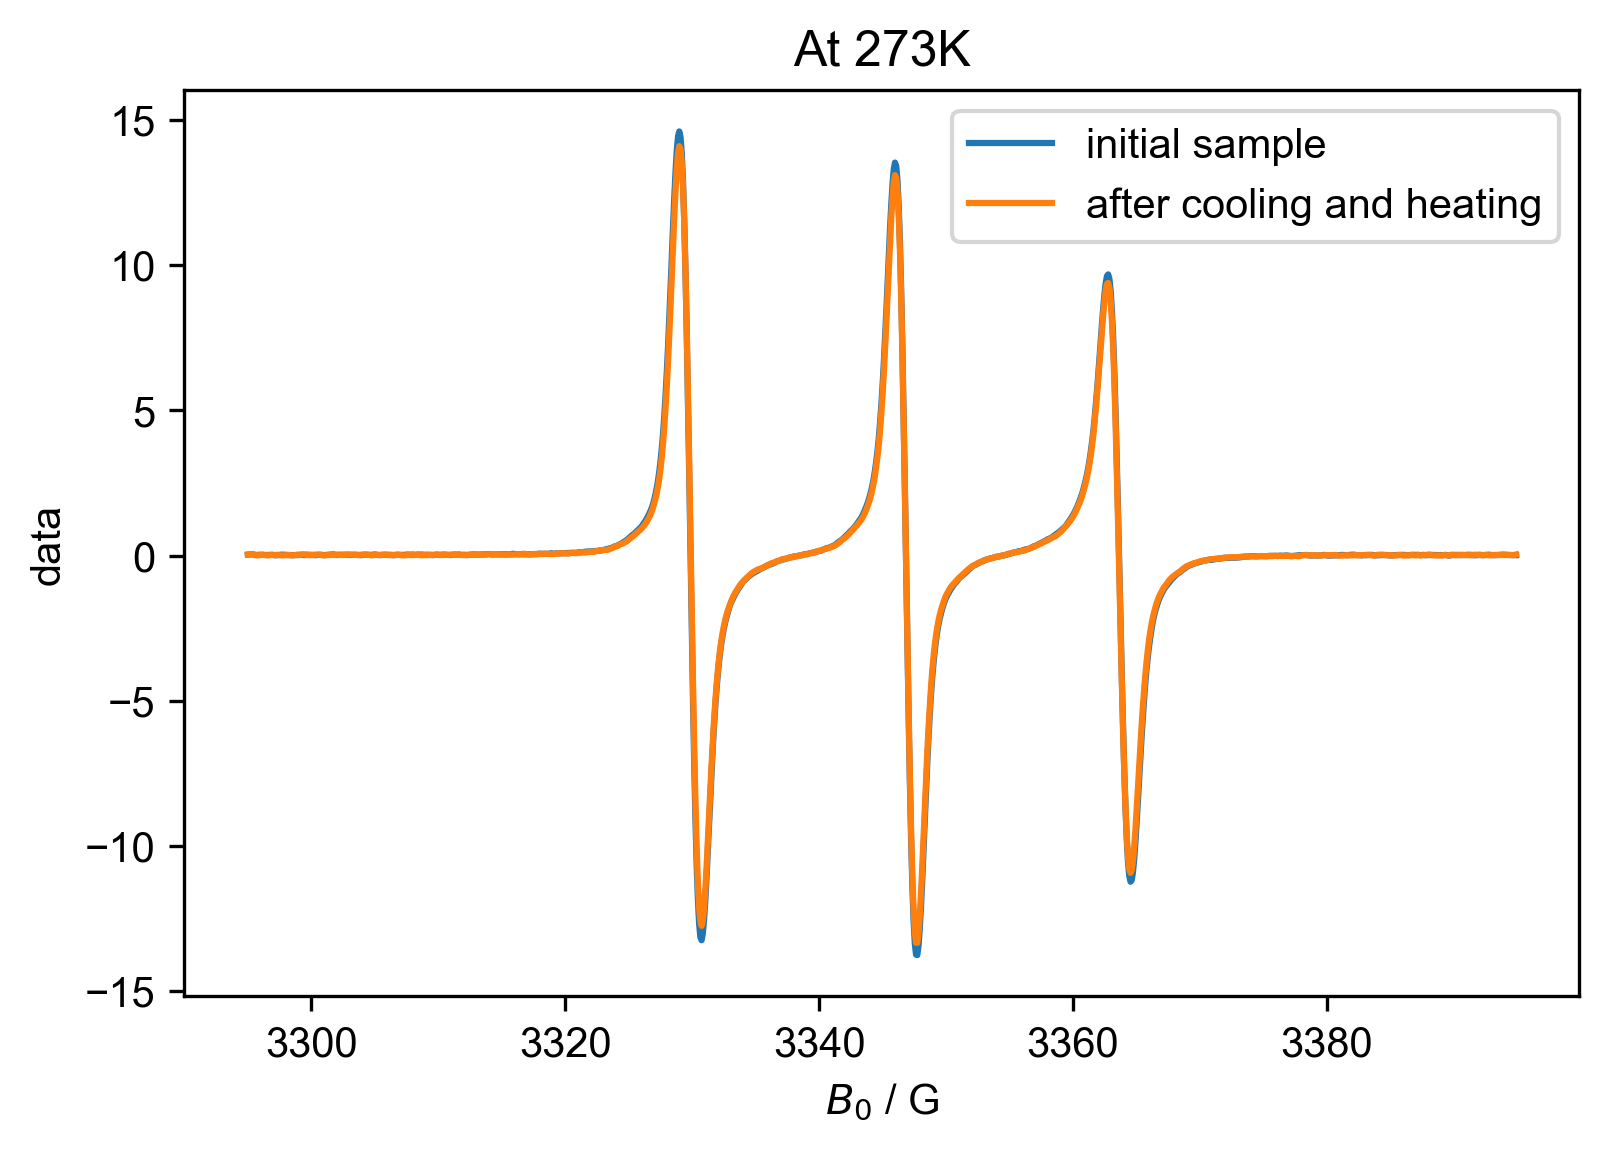

In [13]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":273], label="initial sample")
plot(d2["Temperature":273], label="after cooling and heating")
title("At 273K")
legend()

[253.491 254.575 255.723 256.46  257.447 258.472 259.364 260.438 261.51
 262.476 263.337 264.417 265.457 266.598 267.361 268.588 269.503 270.544
 271.313 272.564 273.58  274.469 275.41  276.489 277.518 278.445 279.702
 280.337 281.631 282.215 283.013]
[253.015 253.677 254.443 255.446 256.526 257.736 258.485 259.482 260.608
 261.536 262.463 263.623 264.495 265.561 266.533 267.581 268.42  269.683
 270.659 271.529 272.563 273.478 274.418 275.65  276.628 277.708 278.622
 279.524 280.831 281.719 282.505]


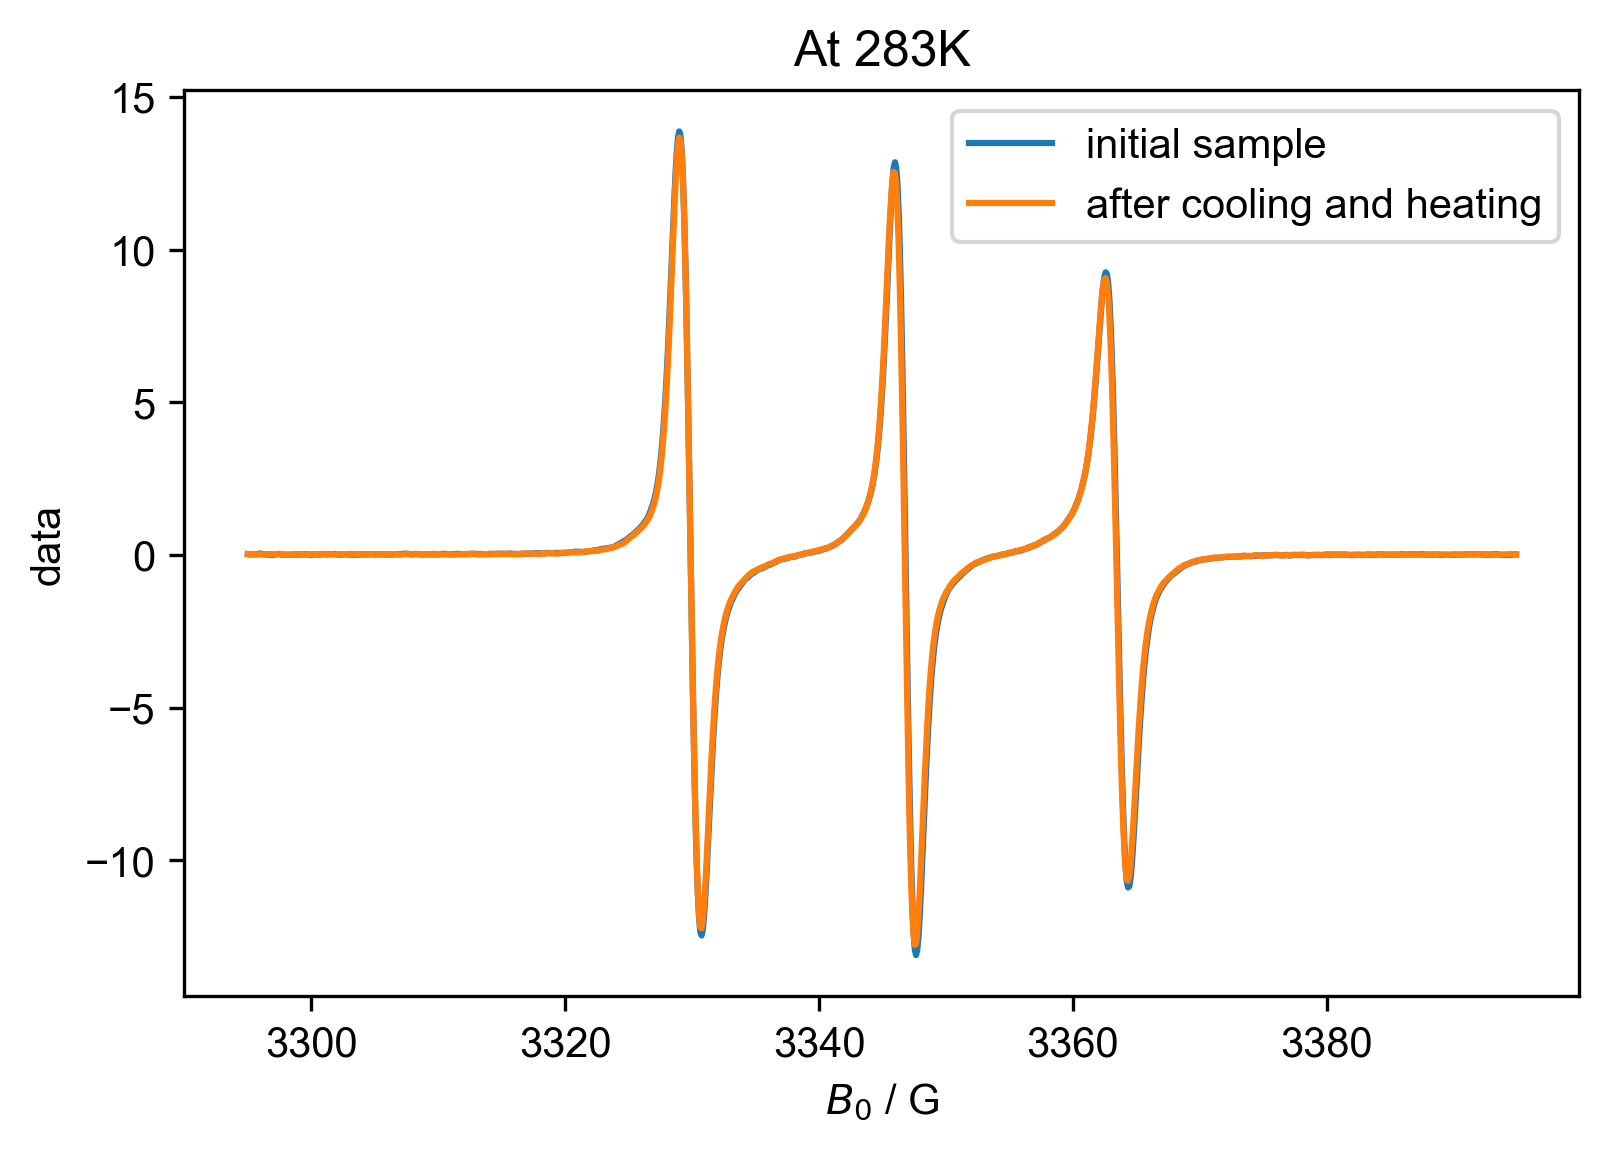

In [14]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":283], label="initial sample")
plot(d2["Temperature":283], label="after cooling and heating")
title("At 283K")
legend()

In [15]:
# #Normalized
# figure(dpi=300, figsize=(7,4))
# plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "initial sample")
# plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "after cooling and heating")
# title("Normalized TEMPO-SO$_4$ w$_0= 20$ in Dodecane near room temperature (283K)")
# legend()